<a href="https://colab.research.google.com/github/AKookani/BrickwallCliffordCircuit/blob/main/Purification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dependencies

In [ ]:
!pip install qiskit ipywidgets
!pip install pylatexenc
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 6.8 MB/s eta 0:00:00


In [ ]:
import numpy as np
import qiskit
import qiskit.quantum_info as qi
import matplotlib.pyplot as plt

In [ ]:
rng = np.random.default_rng() # Random Number Generator

# Stabilizer

## Rank of the restricted global generator matrix $\mathcal{G\vert{}}_A$


*   Rank of the subsystem's generator matrix determines its Entropy.
$$S(A) = \operatorname{rank}(\mathcal{G\vert{}}_A) - |A|, \; \mathcal{G\vert{}}_A\in\mathbb F_2^{L\times 2n}$$
  
    * $L=$ **size of the full system** $=$ **number of generators**
    * $n=$ Columns in $X_A=$ Columns in $Z_A$
*   $\mathcal{G\vert{}}_A$ is a dense $GF(2)$ matrix
    *    **Dense** matrix has mostly non-zero values (in this case 1).
    *   **$GF(2)$** matrix has elements of either 0 or 1, based on **modulo** \\(2\\) arithmetic (Galois Field of order 2).


Rank of $\mathcal{G\vert{}}_A$ is the number of **non-zero rows (pivots)** in **Row Echelon Form ($REF$)** obtained from **Gaussian eliminitaion**

Gaussian elimination permits:

1. **Row Swapping**: \\(R_i\leftrightarrow R_j\\).
2. **Row Addition/Subtraction**: \\(R_i\leftarrow R_i+R_j\\), where addition is XOR over \\(GF(2)\\).
3. **Non-zero Scalar Multiplication**: over \\(GF(2)\\), this has no effect because the only nonzero scalar is \\(1\\).

The general form of a matrix in row-echelon form ($REF$) is:

$$A= \begin{pmatrix} \boxed{*}&*&*&*&*\\\ 0&0&\boxed{*}&*&*\\\ 0&0&0&\boxed{*}&*\\\ 0&0&0&0&0 \end{pmatrix}$$

Here, each \\(\boxed{*}\\) represents a **pivot**.

A $REF$ matrix satisfies these rules:

1. All zero rows are at the bottom.
2. The first non-zero entry in each row is strictly to the left of the first non-zero entry in the row below.
3. All entries below each pivot are zero.

| Scenario | Best Algorithm |
|----------|---------------|
| **Batched, small dense matrices** on GPU | **Gaussian Elimination** |
| **Single, Massive Dense Matrix** (e.g., $n > 5{,}000$ on CPU) | **M4RI** |
| **Single, Massive Sparse Matrix** (e.g., Cryptanalysis on CPU) | **Block Wiedemann** |

In [ ]:
def gf2_rank(matrix):
    m = (matrix.copy() % 2).astype(np.uint8)  # Convert entries to GF(2): 0 or 1
    rows, cols = m.shape
    rank = 0  # Count the pivots found

    for col in range(cols):  # Process column wise
        pivot = None
        for r in range(rank, rows):  # Search for a pivot (1)
            if m[r, col] == 1:
                pivot = r
                break

        if pivot is None:  # No pivot found; skip this column
            continue

        m[[rank, pivot]] = m[[pivot, rank]]  # Move pivot row into position

        for r in range(rows):  # Eliminate other 1s in the pivot column
            if r != rank and m[r, col]:
                m[r] = (m[r] + m[rank]) % 2  # Add rows modulo 2

        rank += 1  # Count the pivot

    return rank  # Rank = total number of pivots

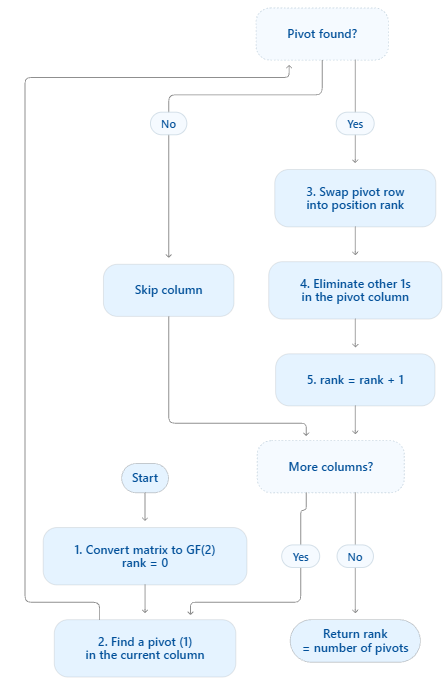

## Entropy of an Ancilla

In [ ]:
def ancilla_entropy(state, ancilla_col=0):
    """S_A = rank_GF2(stabilizer restricted to A) - |A|, for a 1-qubit ancilla."""
    cliff = state.clifford #Get the Clifford representation
    x_col = cliff.stab_x[:, ancilla_col:ancilla_col+1].astype(np.uint8) #Extract the X stabilizers of ancilla
    z_col = cliff.stab_z[:, ancilla_col:ancilla_col+1].astype(np.uint8) #Extract the Z stabilizers of ancilla
    M_A = np.concatenate([x_col, z_col], axis=1) #Build the restricted stabilizer matrix
    return gf2_rank(M_A) - 1 #Yeald the entropy

## Random brickwall Clifford

In [ ]:
def brickwork_layer(state, system_qubits, t, periodic=True):
    """One staggered even/odd brickwork layer of random 2-qubit Cliffords."""
    L = len(system_qubits) #Get system size
    offset = t % 2 #Determine whether this is an even or odd layer
    j = offset #Start brickwork at the correct qubit
    while j + 1 < L:
        u2 = qi.random_clifford(2) #Create a random two-qubit Clifford gates
        state = state.evolve( #Applies generated u2 to the selected neighboring qubits
            qi.Clifford(u2), qargs=[system_qubits[j], system_qubits[j+1]]
            )
        j += 2
    if periodic and offset == 1 and L % 2 == 0: #Periodic boundary condition
        u2 = qi.random_clifford(2) #Create a random two-qubit Clifford gates
        state = state.evolve( #Applies generated u2 to the selected neighboring qubits
            qi.Clifford(u2), qargs=[system_qubits[L-1], system_qubits[0]]
            )
    return state #Return updated state

This function implements **one layer of a 1D brickwork quantum circuit** made of **random two-qubit Clifford gates**. It applies gates in an alternating even/odd pattern, which is common in quantum information simulations of random circuits, scrambling, and entanglement dynamics.

## Measurement

In [ ]:
def measure_layer(state, system_qubits, p_measure):
    """Independently measure EACH system qubit with probability p_measure."""
    for q in system_qubits: #Loop over each qubit of the system
        if rng.random() < p_measure: #Random decision
            outcome, state = state.measure([q])
    return state

This function **randomly performs measurements on individual qubits in a quantum state** with a given probability.

## Trajectory

In [ ]:
def run_trajectory(size, T, p_measure, t_scramble=0, periodic=True):
  #Create registers
    Ancilla = qiskit.QuantumRegister(1, 'ancilla')
    System = qiskit.QuantumRegister(size, 'system')
    qc = qiskit.QuantumCircuit(Ancilla, System)
    system_qubits = list(range(1, size + 1))  # Define system qubit indices; ancilla = 0

    if t_scramble > 0: # Optional Scrambling
        # Phase 1: scramble the system ALONE, no ancilla coupling yet
        qc_sys = qiskit.QuantumCircuit(size)
        state = qi.StabilizerState(qc_sys)
        for t in range(t_scramble):
            state = brickwork_layer(state, list(range(size)), t, periodic=periodic)
        # rebuild as (ancilla + system), then couple
        full_qc = qiskit.QuantumCircuit(Ancilla, System)
        state = qi.StabilizerState(full_qc).evolve(qi.Clifford(state.clifford.to_circuit()),
                                                  qargs=list(range(1, size + 1)))
        state = state.evolve(qi.Clifford(qiskit.QuantumCircuit(1).compose(qiskit.QuantumCircuit(1))), qargs=[0])  # no-op, ancilla stays |0>
        qc2 = qiskit.QuantumCircuit(1)
        qc2.h(0)
        state = state.evolve(qi.Clifford(qc2), qargs=[0])
        cx = qiskit.QuantumCircuit(2); cx.cx(0, 1)
        state = state.evolve(qi.Clifford(cx), qargs=[0, size // 2 + 1])
    else:
        qc.h(Ancilla)
        qc.cx(Ancilla, System[size // 2])
        state = qi.StabilizerState(qc)

    entropy_history = np.zeros(T)
    for t in range(T):
      if t == 0:
        entropy_history[t] = ancilla_entropy(state, ancilla_col=0)
      else:
        state = brickwork_layer(state, system_qubits, t, periodic=periodic)
        state = measure_layer(state, system_qubits, p_measure)
        entropy_history[t] = ancilla_entropy(state, ancilla_col=0)
    return entropy_history

## Plot

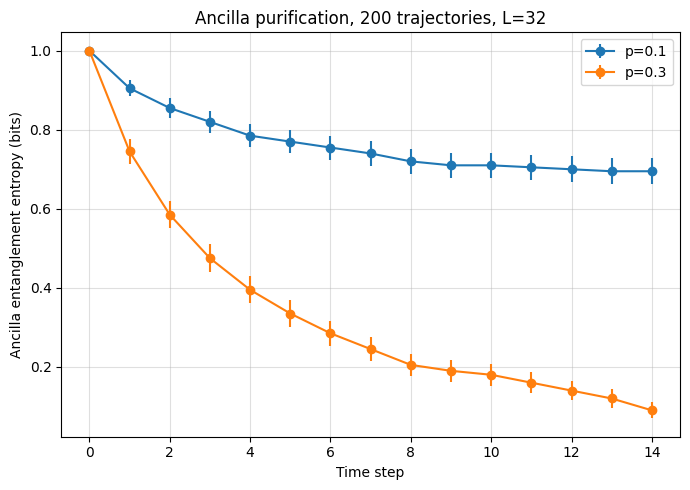

CPU times: user 6min 51s, sys: 540 ms, total: 6min 51s
Wall time: 7min


In [ ]:
%%time
def run_averaged(size, T, p_measure, n_trials=200, t_scramble=0, periodic=True):
    all_S = np.zeros((n_trials, T))
    for k in range(n_trials):
        all_S[k] = run_trajectory(size, T, p_measure, t_scramble=t_scramble, periodic=periodic)
    return all_S.mean(axis=0), all_S.std(axis=0) / np.sqrt(n_trials)

# --- Run and plot ---
size = 32          # even size -> clean periodic brickwork, matches the paper's 2L convention
T = 15
n_trials = 200

plt.figure(figsize=(7, 5))
for p in [0.1, 0.3]:
    mean_S, sem_S = run_averaged(size, T, p, n_trials=n_trials)
    plt.errorbar(range(0, T), mean_S, yerr=sem_S, marker='o', label=f"p={p}")

plt.xlabel("Time step")
plt.ylabel("Ancilla entanglement entropy (bits)")
plt.title(f"Ancilla purification, {n_trials} trajectories, L={size}")
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# Circuit

Example system with the size=6, Depth=6, and measurement rate=0.4 


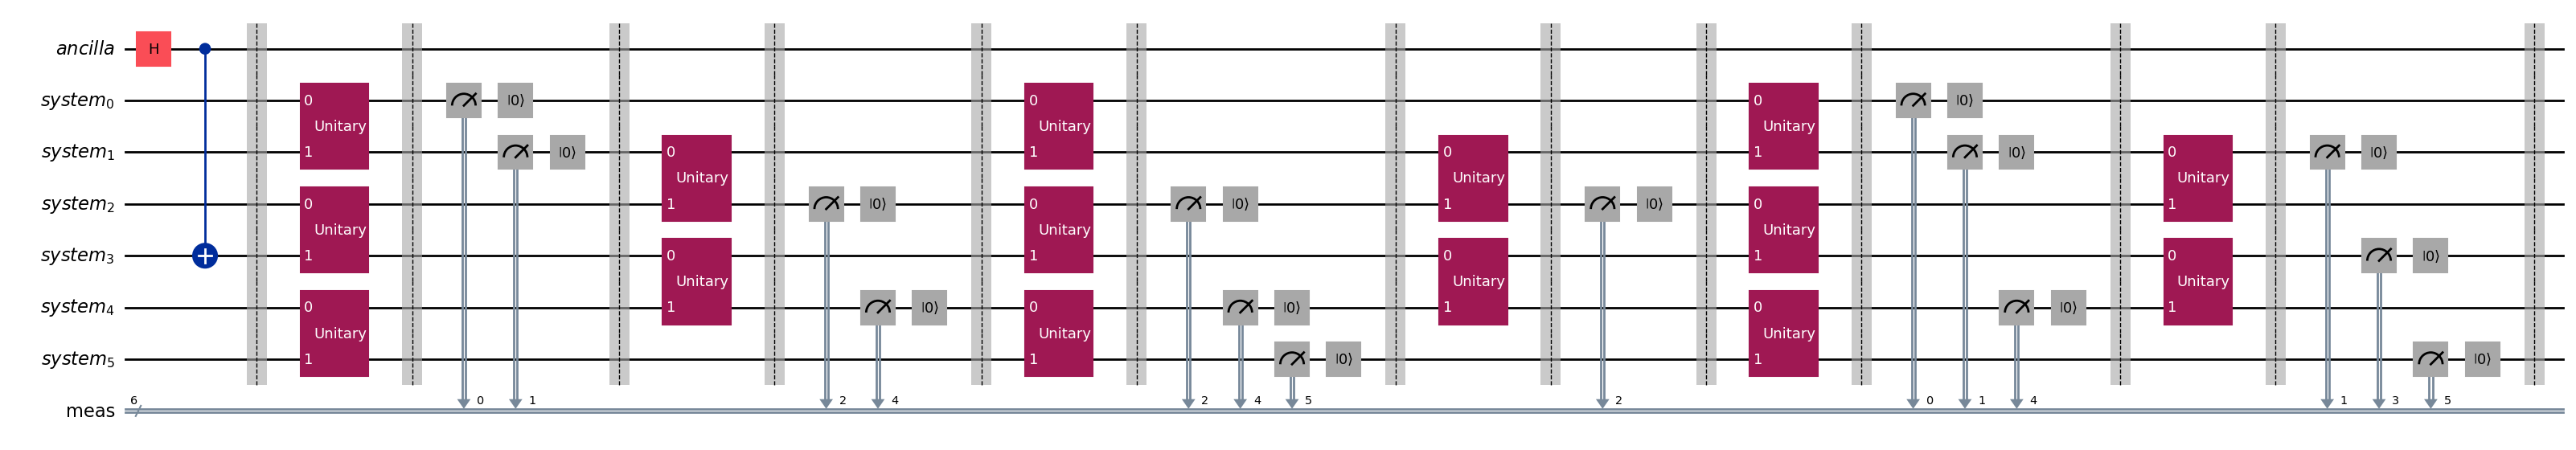

p=0.00  <S_ancilla>=1.000 ± 0.000
p=0.10  <S_ancilla>=0.761 ± 0.025
p=0.20  <S_ancilla>=0.485 ± 0.033
p=0.30  <S_ancilla>=0.318 ± 0.028
p=0.40  <S_ancilla>=0.131 ± 0.020
p=0.60  <S_ancilla>=0.015 ± 0.007
p=0.80  <S_ancilla>=0.000 ± 0.000


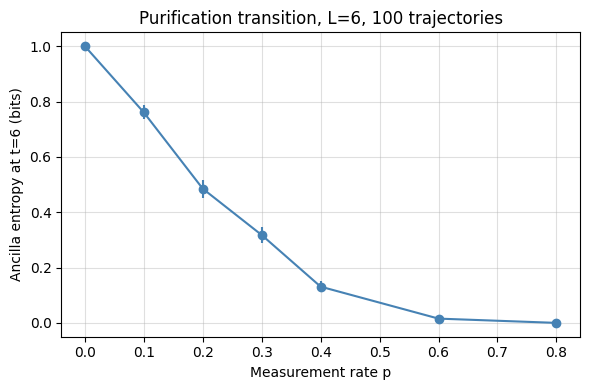

In [ ]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import random_unitary, partial_trace, entropy
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

rng = np.random.default_rng()
sim = AerSimulator(method='density_matrix')


def build_trajectory_circuit(size, T, p_measure, seed=None):
    """
    Ancilla (qubit 0) Bell-paired to the middle system qubit, followed by
    T brickwork layers of random 2-qubit unitaries with per-qubit
    mid-circuit measurement/reset at rate p_measure.
    """
    local_rng = np.random.default_rng(seed)

    Ancilla = QuantumRegister(1, 'ancilla')
    System = QuantumRegister(size, 'system')
    Creg = ClassicalRegister(size, 'meas')
    qc = QuantumCircuit(Ancilla, System, Creg)

    # Entangle ancilla with the middle system qubit
    qc.h(Ancilla[0])
    qc.cx(Ancilla[0], System[size // 2])
    qc.barrier()

    system_qubits = list(range(1, size + 1))  # global indices (0 = ancilla)

    for t in range(T):
        # --- brickwork layer of random 2-qubit gates ---
        offset = t % 2
        j = offset
        while j + 1 < size:
            u2 = random_unitary(4, seed=local_rng.integers(1 << 30))
            qc.append(UnitaryGate(u2), [system_qubits[j], system_qubits[j + 1]])
            j += 2
        qc.barrier()

        # --- per-qubit measurement with probability p_measure ---
        for k, q in enumerate(system_qubits):
            if local_rng.random() < p_measure:
                qc.measure(q, Creg[k])
                qc.reset(q)
        qc.barrier()

    return qc


def run_trajectory(size, T, p_measure, seed=None):
    qc = build_trajectory_circuit(size, T, p_measure, seed=seed)
    qc.save_density_matrix()
    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=1).result()
    rho_full = result.data(0)['density_matrix']
    rho_ancilla = partial_trace(rho_full, list(range(1, size + 1)))
    return entropy(rho_ancilla, base=2)


def run_averaged(size, T, p_measure, n_trials=100):
    entropies = np.array([
        run_trajectory(size, T, p_measure, seed=trial)
        for trial in range(n_trials)
    ])
    return entropies.mean(), entropies.std() / np.sqrt(n_trials)


# --- Show one example circuit for presentation ---
example_qc = build_trajectory_circuit(size=6, T=6, p_measure=0.4, seed=0)
print("Example system with the size=6, Depth=6, and measurement rate=0.4 ")
display(example_qc.draw('mpl', fold=-1))

# --- Sweep over measurement rate p, averaging entropy at final time T ---
size = 6
T = 6
n_trials = 100
p_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8]

mean_entropies = []
sem_entropies = []
for p in p_values:
    m, s = run_averaged(size, T, p, n_trials=n_trials)
    mean_entropies.append(m)
    sem_entropies.append(s)
    print(f"p={p:.2f}  <S_ancilla>={m:.3f} ± {s:.3f}")

plt.figure(figsize=(6, 4))
plt.errorbar(p_values, mean_entropies, yerr=sem_entropies, marker='o', color='steelblue')
plt.xlabel("Measurement rate p")
plt.ylabel(f"Ancilla entropy at t={T} (bits)")
plt.title(f"Purification transition, L={size}, {n_trials} trajectories")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

Example system with the size=6, Depth=6, and measurement rate=0.4 


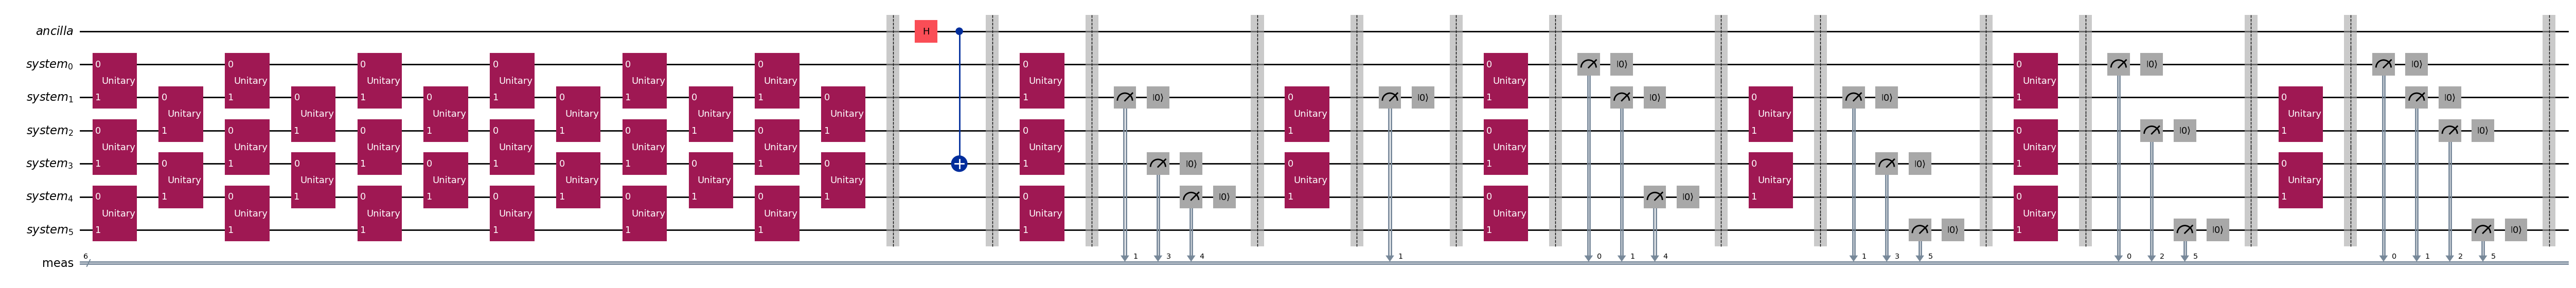

p=0.00  <S_ancilla>=0.988 ± 0.002
p=0.10  <S_ancilla>=0.853 ± 0.017
p=0.20  <S_ancilla>=0.619 ± 0.027
p=0.30  <S_ancilla>=0.412 ± 0.032
p=0.40  <S_ancilla>=0.215 ± 0.029
p=0.60  <S_ancilla>=0.018 ± 0.007
p=0.80  <S_ancilla>=0.001 ± 0.001


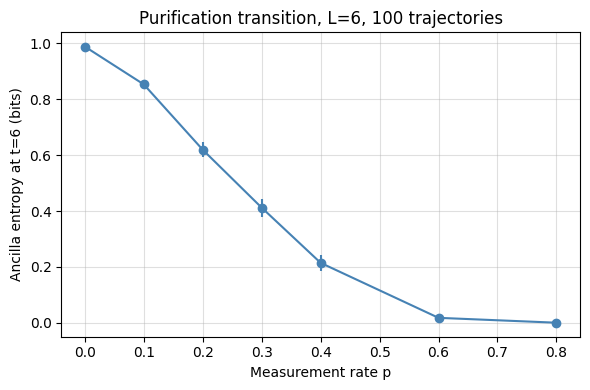

In [ ]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import random_unitary, partial_trace, entropy
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

rng = np.random.default_rng()
sim = AerSimulator(method='density_matrix')


def build_trajectory_circuit_scrambled(size, T, p_measure, t_scramble=4, seed=None):
    local_rng = np.random.default_rng(seed)

    Ancilla = QuantumRegister(1, 'ancilla')
    System = QuantumRegister(size, 'system')
    Creg = ClassicalRegister(size, 'meas')
    qc = QuantumCircuit(Ancilla, System, Creg)

    system_qubits_local = list(range(size))       # 0-indexed within System register
    system_qubits_global = list(range(1, size+1)) # global indices (0 = ancilla)

    # --- Phase 1: scramble the system ALONE, ancilla untouched ---
    for t in range(t_scramble):
        offset = t % 2
        j = offset
        while j + 1 < size:
            u2 = random_unitary(4, seed=local_rng.integers(1 << 30))
            qc.append(UnitaryGate(u2), [System[j], System[j + 1]])
            j += 2
    qc.barrier()

    # --- Phase 2: NOW couple ancilla to the scrambled system ---
    qc.h(Ancilla[0])
    qc.cx(Ancilla[0], System[size // 2])
    qc.barrier()

    # --- Phase 3: monitored dynamics (same as before) ---
    for t in range(T):
        offset = t % 2
        j = offset
        while j + 1 < size:
            u2 = random_unitary(4, seed=local_rng.integers(1 << 30))
            qc.append(UnitaryGate(u2), [system_qubits_global[j], system_qubits_global[j + 1]])
            j += 2
        qc.barrier()

        for k, q in enumerate(system_qubits_global):
            if local_rng.random() < p_measure:
                qc.measure(q, Creg[k])
                qc.reset(q)
        qc.barrier()

    return qc


def run_trajectory(size, T, p_measure, seed=None):
    qc = build_trajectory_circuit_scrambled(size, T, p_measure, scramble, seed=seed)
    qc.save_density_matrix()
    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=1).result()
    rho_full = result.data(0)['density_matrix']
    rho_ancilla = partial_trace(rho_full, list(range(1, size + 1)))
    return entropy(rho_ancilla, base=2)


def run_averaged(size, T, p_measure, n_trials=100):
    entropies = np.array([
        run_trajectory(size, T, p_measure, seed=trial)
        for trial in range(n_trials)
    ])
    return entropies.mean(), entropies.std() / np.sqrt(n_trials)


# --- Show one example circuit for presentation ---
example_qc = build_trajectory_circuit_scrambled(size=6, T=6, p_measure=0.4, t_scramble=12, seed=0)
print("Example system with the size=6, Depth=6, and measurement rate=0.4 ")
display(example_qc.draw('mpl', fold=-1))

# --- Sweep over measurement rate p, averaging entropy at final time T ---
size = 6
T = 6
scramble = 12
n_trials = 100
p_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8]

mean_entropies = []
sem_entropies = []
for p in p_values:
    m, s = run_averaged(size, T, p, n_trials=n_trials)
    mean_entropies.append(m)
    sem_entropies.append(s)
    print(f"p={p:.2f}  <S_ancilla>={m:.3f} ± {s:.3f}")

plt.figure(figsize=(6, 4))
plt.errorbar(p_values, mean_entropies, yerr=sem_entropies, marker='o', color='steelblue')
plt.xlabel("Measurement rate p")
plt.ylabel(f"Ancilla entropy at t={T} (bits)")
plt.title(f"Purification transition, L={size}, {n_trials} trajectories")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

# GPU

device: cuda


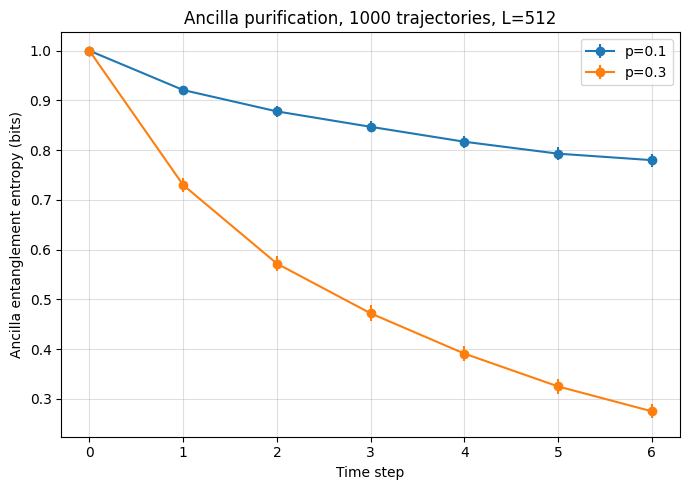

CPU times: user 1min 26s, sys: 3.75 s, total: 1min 30s
Wall time: 1min 32s


In [ ]:
%%time

import numpy as np
import torch
import os

# ---------------- Sp(4,2) precomputation (720 elements, one-time, cached) ----------------

def gf2_rank_full(matrix):
    m = (matrix.copy() % 2).astype(np.uint8)
    rows, cols = m.shape
    rank = 0
    for col in range(cols):
        pivot = None
        for r in range(rank, rows):
            if m[r, col]:
                pivot = r
                break
        if pivot is None:
            continue
        m[[rank, pivot]] = m[[pivot, rank]]
        for r in range(rows):
            if r != rank and m[r, col]:
                m[r] = (m[r] + m[rank]) % 2
        rank += 1
    return rank


def build_sp42(cache_path="sp42_table.npy"):
    if os.path.exists(cache_path):
        return np.load(cache_path)
    idx = np.arange(1 << 16, dtype=np.uint32)
    bits = ((idx[:, None] >> np.arange(16)) & 1).astype(np.uint8)
    mats = bits.reshape(-1, 4, 4)
    J = np.array([[0, 1, 0, 0],
                  [1, 0, 0, 0],
                  [0, 0, 0, 1],
                  [0, 0, 1, 0]], dtype=np.uint8)
    valid = []
    for M in mats:
        if gf2_rank_full(M) < 4:
            continue
        lhs = (M.T.astype(np.uint8) @ J @ M) % 2
        if np.array_equal(lhs, J):
            valid.append(M)
    table = np.stack(valid).astype(np.uint8)
    np.save(cache_path, table)
    return table


# ---------------- Tableau gate primitives (batched, in-place where possible) ----------------

def apply_hadamard(X, Z, q):
    xq = X[:, :, q].clone()
    zq = Z[:, :, q].clone()
    X[:, :, q] = zq
    Z[:, :, q] = xq


def apply_cnot(X, Z, c, t):
    X[:, :, t] ^= X[:, :, c]
    Z[:, :, c] ^= Z[:, :, t]


def apply_two_qubit_random(X, Z, a, b, sp42_table, batch, device, generator=None):
    n_elems = sp42_table.shape[0]
    idx = torch.randint(0, n_elems, (batch,), device=device, generator=generator)
    M = sp42_table[idx].float()  # (batch,4,4)
    vec = torch.stack([X[:, :, a], Z[:, :, a], X[:, :, b], Z[:, :, b]], dim=-1).float()  # (batch,n,4)
    new_vec = torch.einsum('bkl,bnl->bnk', M, vec)
    new_vec = torch.remainder(new_vec, 2).to(torch.uint8)
    X[:, :, a] = new_vec[..., 0]
    Z[:, :, a] = new_vec[..., 1]
    X[:, :, b] = new_vec[..., 2]
    Z[:, :, b] = new_vec[..., 3]


def brickwork_layer_batched(X, Z, t, system_qubits, sp42_table, batch, device, periodic=True, generator=None):
    L = len(system_qubits)
    offset = t % 2
    j = offset
    while j + 1 < L:
        apply_two_qubit_random(X, Z, system_qubits[j], system_qubits[j + 1], sp42_table, batch, device, generator)
        j += 2
    if periodic and offset == 1 and L % 2 == 0:
        apply_two_qubit_random(X, Z, system_qubits[L - 1], system_qubits[0], sp42_table, batch, device, generator)


def measure_layer_batched(X, Z, system_qubits, p_measure, batch, device, generator=None):
    do_measure = torch.rand((batch, len(system_qubits)), device=device, generator=generator) < p_measure
    b_idx = torch.arange(batch, device=device)
    for k, q in enumerate(system_qubits):
        mask_q = do_measure[:, k]
        if not mask_q.any():
            continue
        x_col = X[:, :, q]
        anticommute = (x_col == 1)
        any_anti = anticommute.any(dim=1)
        is_random = any_anti & mask_q
        if not is_random.any():
            continue
        pivot_idx = torch.argmax(anticommute.to(torch.int64), dim=1)
        pivot_X = X[b_idx, pivot_idx, :].clone()
        pivot_Z = Z[b_idx, pivot_idx, :].clone()
        upd_mask = anticommute.clone()
        upd_mask[b_idx, pivot_idx] = False
        upd_mask = (upd_mask & is_random.unsqueeze(1)).to(torch.uint8)
        X ^= upd_mask.unsqueeze(-1) * pivot_X.unsqueeze(1)
        Z ^= upd_mask.unsqueeze(-1) * pivot_Z.unsqueeze(1)
        reset_x_row = torch.zeros_like(pivot_X)
        reset_z_row = torch.zeros_like(pivot_Z)
        reset_z_row[:, q] = 1
        sel = is_random  # (batch,)
        new_pivot_X = torch.where(sel.unsqueeze(-1), reset_x_row, pivot_X)
        new_pivot_Z = torch.where(sel.unsqueeze(-1), reset_z_row, pivot_Z)
        X[b_idx, pivot_idx, :] = new_pivot_X
        Z[b_idx, pivot_idx, :] = new_pivot_Z
    return X, Z


def ancilla_entropy_batched(X, Z, ancilla_col=0):
    x_col = X[:, :, ancilla_col]
    z_col = Z[:, :, ancilla_col]
    pat1 = ((x_col == 0) & (z_col == 1)).any(dim=1)
    pat2 = ((x_col == 1) & (z_col == 0)).any(dim=1)
    pat3 = ((x_col == 1) & (z_col == 1)).any(dim=1)
    distinct = pat1.to(torch.int64) + pat2.to(torch.int64) + pat3.to(torch.int64)
    rank = torch.clamp(distinct, max=2)
    return (rank - 1).float()


def run_averaged_gpu(size, T, p_measure, n_trials=1000, periodic=True, device=None, sp42_table=None, seed=None):
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if sp42_table is None:
        sp42_table = torch.tensor(build_sp42(), dtype=torch.uint8, device=device)
    generator = None
    if seed is not None:
        generator = torch.Generator(device=device)
        generator.manual_seed(seed)

    n = size + 1
    system_qubits = list(range(1, size + 1))
    X = torch.zeros((n_trials, n, n), dtype=torch.uint8, device=device)
    Z = torch.zeros((n_trials, n, n), dtype=torch.uint8, device=device)
    Z[:, torch.arange(n), torch.arange(n)] = 1

    apply_hadamard(X, Z, 0)
    apply_cnot(X, Z, 0, size // 2 + 1)

    entropy_hist = torch.zeros((n_trials, T), device=device)
    entropy_hist[:, 0] = ancilla_entropy_batched(X, Z, 0)
    for t in range(1, T):
        brickwork_layer_batched(X, Z, t, system_qubits, sp42_table, n_trials, device, periodic=periodic, generator=generator)
        X, Z = measure_layer_batched(X, Z, system_qubits, p_measure, n_trials, device, generator=generator)
        entropy_hist[:, t] = ancilla_entropy_batched(X, Z, 0)

    mean_S = entropy_hist.mean(dim=0).cpu().numpy()
    sem_S = (entropy_hist.std(dim=0) / (n_trials ** 0.5)).cpu().numpy()
    return mean_S, sem_S


if __name__ == "__main__":
    import matplotlib.pyplot as plt

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print("device:", device)
    table = build_sp42()  # cached to sp42_table.npy after first run
    sp42_t = torch.tensor(table, dtype=torch.uint8, device=device)

    size = 512
    T = 7
    n_trials = 1000

    plt.figure(figsize=(7, 5))
    for p in [0.1, 0.3]:
        mean_S, sem_S = run_averaged_gpu(
            size=size, T=T, p_measure=p, n_trials=n_trials,
            sp42_table=sp42_t, device=device,
        )
        plt.errorbar(range(0, T), mean_S, yerr=sem_S, marker='o', label=f"p={p}")

    plt.xlabel("Time step")
    plt.ylabel("Ancilla entanglement entropy (bits)")
    plt.title(f"Ancilla purification, {n_trials} trajectories, L={size}")
    plt.legend()
    plt.grid(alpha=0.4)
    plt.tight_layout()
    plt.savefig("mipt_result.png", dpi=150)
    plt.show()